# Demo del clasificador de exoplanetas (v3)

Carga el modelo entrenado (`data/model.pkl`) y muestra tres KOIs del **test held-out**
(estrellas que el modelo no vio al entrenar): un CONFIRMED bien clasificado, un FALSE POSITIVE
bien clasificado y un error. Cada fila del dataset v3 es un **KOI** (un candidato), y la curva se
dobla con la **efeméride del catálogo** (período y época del tránsito), no con un período buscado por BLS.
Las columnas `koi_*` se usan solo para doblar y enmascarar, nunca como features del modelo.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from koi_features import (FEATURE_COLUMNS_V3, LC_CACHE_DIR, _other_mask, cached_kepids,
                          load_catalog, prepare_star, select_kois, time_from_midtransit)
from train_model import MISCLASSIFIED_PATH, MODEL_PATH, heldout_split, load_dataset_v3

# koi_features fija el backend Agg al importarse; acá queremos ver las figuras en el notebook.
%matplotlib inline

model = joblib.load(MODEL_PATH)
df = load_dataset_v3()

/home/eneas/Joaquin/Desarrollo/Joaquin/exoplanetas/venv/lib/python3.14/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## Reconstruir el test held-out
`heldout_split` es la misma función que usa `train_model.py` (split 80/20 agrupado por `kepid`),
así que obtenemos exactamente los mismos KOIs de test.

In [2]:
_, te = heldout_split(df)
test = df.iloc[te].copy()
test["p_confirmed"] = model.predict_proba(test[FEATURE_COLUMNS_V3])[:, 1]
test["pred"] = (test.p_confirmed >= 0.5).astype(int)
print(f"Test: {len(test)} KOIs, aciertos: {(test.pred == test.y).mean():.1%}")

Test: 97 KOIs, aciertos: 79.4%


## Elegir los tres KOIs
- **Acierto CONFIRMED**: el CONFIRMED con mayor probabilidad asignada.
- **Acierto FALSE POSITIVE**: el FALSE POSITIVE con menor probabilidad de ser planeta.
- **Error**: el error más "seguro" (mayor confianza en la clase equivocada), de `data/misclassified.csv`.

In [3]:
ok_conf = test[(test.y == 1) & (test.pred == 1)].nlargest(1, "p_confirmed").iloc[0]
ok_fp = test[(test.y == 0) & (test.pred == 0)].nsmallest(1, "p_confirmed").iloc[0]

mis = pd.read_csv(MISCLASSIFIED_PATH)
mis["confidence"] = np.where(mis.true_label == "CONFIRMED",
                             1 - mis.predicted_proba_confirmed, mis.predicted_proba_confirmed)
bad = mis.nlargest(1, "confidence").iloc[0]

cases = [
    ("Bien clasificado: CONFIRMED", ok_conf.kepoi_name),
    ("Bien clasificado: FALSE POSITIVE", ok_fp.kepoi_name),
    ("MAL clasificado", bad.kepoi_name),
]
test.set_index("kepoi_name").loc[[c[1] for c in cases],
    ["label", "p_confirmed", "shape_uv_ratio", "log_transit_snr", "log_asymmetry_sigma"]]

,label,p_confirmed,shape_uv_ratio,log_transit_snr,log_asymmetry_sigma
kepoi_name,,,,,
K01831.01,CONFIRMED,1.000000,1.127085,1.323150,0.460262
K03666.01,FALSE POSITIVE,0.000000,1.706472,2.954091,1.197216
K03030.01,FALSE POSITIVE,0.963333,1.168978,1.036044,0.458442


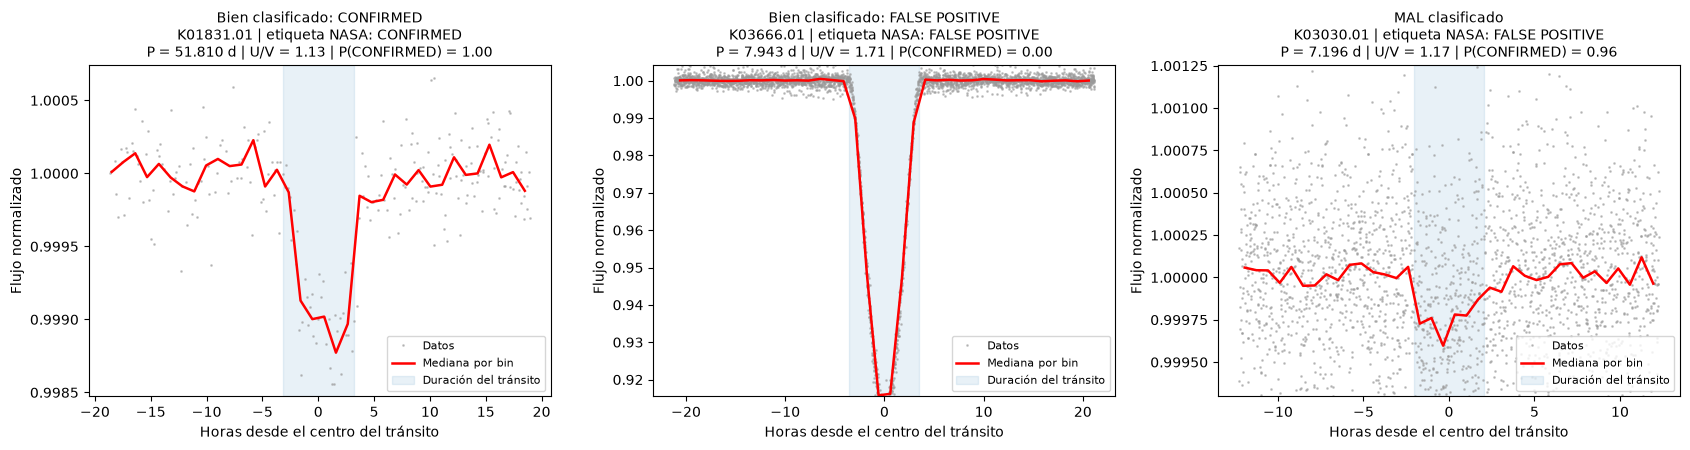

In [4]:
_, all_kois = select_kois(load_catalog(), cached_kepids())


def folded(kepoi):
    """Curva de la estrella doblada con la efeméride del catálogo para ese KOI."""
    row = df[df.kepoi_name == kepoi].iloc[0]
    star_kois = all_kois[all_kois.kepid == row.kepid]
    koi = star_kois[star_kois.kepoi_name == kepoi].iloc[0]
    lc, _ = prepare_star(pd.read_csv(LC_CACHE_DIR / f"KIC_{row.kepid}_lc.csv"), star_kois)
    keep = ~_other_mask(lc.time.values, koi, star_kois)  # sin tránsitos de otros KOIs
    t, f = lc.time.values[keep], lc.flux.values[keep]
    P, D = koi.koi_period, koi.koi_duration / 24
    dt_h = time_from_midtransit(t, P, koi.koi_time0bk) * 24
    return row, P, D, dt_h, f


fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (title, kepoi) in zip(axes, cases):
    row, P, D, dt_h, f = folded(kepoi)
    p = test.set_index("kepoi_name").loc[kepoi, "p_confirmed"]
    sel = np.abs(dt_h) < 3 * D * 24
    ax.plot(dt_h[sel], f[sel], ".", ms=2, color="0.6", alpha=0.5, label="Datos")
    edges = np.linspace(-3 * D * 24, 3 * D * 24, 37)
    idx = np.digitize(dt_h[sel], edges)
    med = [np.median(f[sel][idx == i]) if (idx == i).any() else np.nan for i in range(1, len(edges))]
    ax.plot((edges[:-1] + edges[1:]) / 2, med, "r-", lw=1.8, label="Mediana por bin")
    ax.axvspan(-D * 12, D * 12, color="C0", alpha=0.1, label="Duración del tránsito")
    ax.set_ylim(np.nanmin(med) - 3e-4, np.percentile(f[sel], 99.8))
    ax.ticklabel_format(axis="y", useOffset=False)
    ax.set_xlabel("Horas desde el centro del tránsito")
    ax.set_ylabel("Flujo normalizado")
    ax.set_title(f"{title}\n{kepoi} | etiqueta NASA: {row.label}\n"
                 f"P = {P:.3f} d | U/V = {row.shape_uv_ratio:.2f} | P(CONFIRMED) = {p:.2f}", fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

## Cómo leer las figuras
Un tránsito planetario típico es una caída pequeña, **simétrica** y de **fondo plano** (forma de "U" con
bordes algo redondeados). Una binaria eclipsante suele dar una caída más profunda y en "V".
`U/V` es la feature `shape_uv_ratio`: ~1.0-1.3 es una U, ~1.7 es una V.

- **CONFIRMED bien clasificado (K01831.01, P(CONFIRMED) = 1.00):** caída de ~1000 ppm, de fondo bastante plano
  y bordes marcados, simétrica entre la entrada y la salida (`U/V` = 1.13, forma de U). Es lo que se espera de un planeta.
- **FALSE POSITIVE bien clasificado (K03666.01, P(CONFIRMED) = 0.00):** la caída llega a ~8 % del flujo
  (un planeta no tapa tanta luz de su estrella) y tiene forma de **V** (`U/V` = 1.71), típica de una binaria eclipsante.
  Con una señal tan profunda y en V el modelo no duda.
- **Error del modelo (K03030.01, P(CONFIRMED) = 0.96, pero la etiqueta es FALSE POSITIVE):** la caída es muy
  pequeña (~250 ppm) y la curva es ruidosa, pero se ve una U razonablemente simétrica (`U/V` = 1.17), o sea lo mismo que
  mostraría un planeta. El modelo solo ve las 9 features de la curva de luz, así que no puede detectar las razones por las
  que NASA lo descartó (por ejemplo, que la señal venga de una estrella vecina, algo que se mide con otros datos).
  Es una hipótesis: desde esta figura no se puede comprobar.

Recordá que el clasificador **no ve la imagen**, solo los números; y que en el test hay solo 97 KOIs,
así que un único error cambia bastante las métricas.